# VaR backtest 2022

In [ ]:
!pip install --upgrade yfinance

  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.66
    Uninstalling yfinance-0.2.66:
      Successfully uninstalled yfinance-0.2.66


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm
from scipy.stats import t as student_t

In [ ]:
window = 250
alpha = 0.01
start_date = "2015-01-01"
end_date = "2023-01-01"
tickers = ["SPY",  "AGG"]
weights = pd.Series({"SPY": 0.6, "AGG": 0.4})

## Data and portfolio returns

In [ ]:
prices = yf.download(tickers, start=start_date, end=end_date)["Close"]
print(prices.head())
prices.isna().sum()

[*********************100%***********************]  2 of 2 completed

Ticker            AGG         SPY
Date                             
2015-01-02  79.246971  169.267563
2015-01-05  79.419205  166.210602
2015-01-06  79.620186  164.645065
2015-01-07  79.605789  166.696747
2015-01-08  79.483780  169.654770


,0
Ticker,
AGG,0
SPY,0


In [ ]:
returns = prices.pct_change().dropna()
print(returns.head())

Ticker           AGG       SPY
Date                          
2015-01-05  0.002173 -0.018060
2015-01-06  0.002531 -0.009419
2015-01-07 -0.000181  0.012461
2015-01-08 -0.001533  0.017745
2015-01-09  0.002438 -0.008013


Date
2015-01-05   -0.009967
2015-01-06   -0.004639
2015-01-07    0.007404
2015-01-08    0.010034
2015-01-09   -0.003833
dtype: float64
count    2013.000000
mean        0.000284
std         0.007250
min        -0.073410
25%        -0.002294
50%         0.000416
75%         0.003474
max         0.057665
dtype: float64
Excess kurtosis (2015–2022): 15.34


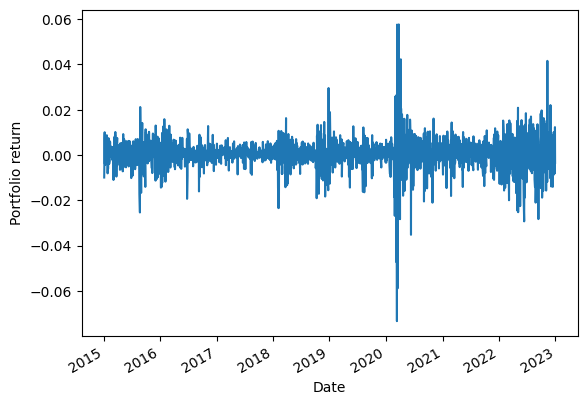

Cumulative portfolio return during 2022:
Date
2022-01-03    0.000739
2022-01-04    0.000503
2022-01-05   -0.012261
2022-01-06   -0.013237
2022-01-07   -0.016733
                ...   
2022-12-23   -0.152219
2022-12-27   -0.156682
2022-12-28   -0.163560
2022-12-29   -0.153286
2022-12-30   -0.156223
Length: 251, dtype: float64


In [ ]:
portfolio = returns.mul(weights, axis=1).sum(axis=1)
print(portfolio.head())
print(portfolio.describe())
print(f"Excess kurtosis (2015–2022): {portfolio.kurtosis():.2f}")
portfolio.plot(xlabel="Date", ylabel="Portfolio return")
plt.show()

print("Cumulative portfolio return during 2022:")
print((portfolio.loc["2022"] + 1).cumprod() - 1)

## Historical VaR

In [ ]:
var_single = portfolio.quantile(alpha)
print(f"Historical 99% VaR, full sample 2015–2022: {var_single:.2%}")

Historical 99% VaR, full sample 2015–2022: -2.04%


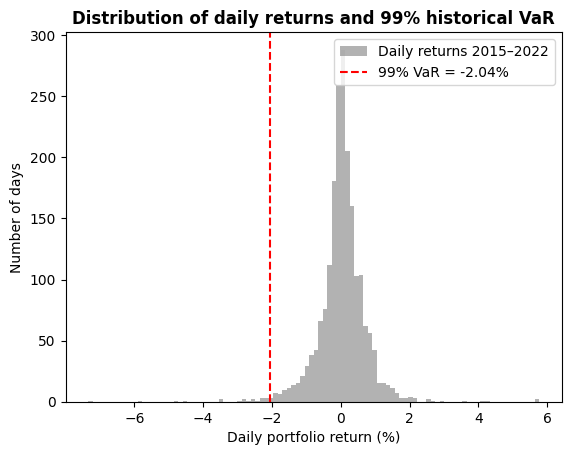

In [ ]:
plt.hist(portfolio * 100, bins=100, color="grey", alpha=0.6, label="Daily returns 2015–2022")
plt.axvline(var_single * 100, color="red", linestyle="dashed", linewidth=1.5,
            label=f"99% VaR = {var_single:.2%}")

plt.xlabel("Daily portfolio return (%)")
plt.ylabel("Number of days")
plt.title("Distribution of daily returns and 99% historical VaR", fontweight="bold")
plt.legend()
plt.show()

In [ ]:
var_hist = portfolio.rolling(window).quantile(alpha).shift(1)
print(var_hist.head())
print(f"Historical VaR on 2022-12-30: {var_hist.iloc[-1]:.2%}")
print(f"Missing values (first window): {var_hist.isna().sum()}")

Date
2015-01-05   NaN
2015-01-06   NaN
2015-01-07   NaN
2015-01-08   NaN
2015-01-09   NaN
dtype: float64
Historical VaR on 2022-12-30: -2.49%
Missing values (first window): 250


In [ ]:
backtest_data = pd.concat([portfolio, var_hist], axis = 1)
backtest_data.columns = ["portfolio", "var_hist"]
print(backtest_data.head())
backtest_data.loc["2022"].isna().sum()

            portfolio  var_hist
Date                           
2015-01-05  -0.009967       NaN
2015-01-06  -0.004639       NaN
2015-01-07   0.007404       NaN
2015-01-08   0.010034       NaN
2015-01-09  -0.003833       NaN


,0
portfolio,0
var_hist,0


In [ ]:
exceptions_hist = backtest_data.loc["2022", "portfolio"] < backtest_data.loc["2022", "var_hist"]
print(exceptions_hist.head())
data_22_hist = backtest_data.loc["2022", ["portfolio", "var_hist"]]
exc_22_hist = data_22_hist.loc[exceptions_hist]
print(exc_22_hist)

Date
2022-01-03    False
2022-01-04    False
2022-01-05    False
2022-01-06    False
2022-01-07    False
dtype: bool
            portfolio  var_hist
Date                           
2022-02-03  -0.015714 -0.013411
2022-02-10  -0.014475 -0.013957
2022-03-07  -0.020009 -0.013957
2022-04-22  -0.016852 -0.014315
2022-04-26  -0.016141 -0.015107
2022-04-29  -0.024570 -0.015932
2022-05-05  -0.025286 -0.016504
2022-05-18  -0.022582 -0.018653
2022-06-13  -0.029338 -0.021559
2022-09-13  -0.028338 -0.023596


In [ ]:
expected_count_hist = len(data_22_hist) * alpha
actual_count_hist = exceptions_hist.sum()
print(f"Exceptions in 2022 (historical): {actual_count_hist} (expected: {expected_count_hist:.2f})")

Exceptions in 2022 (historical): 10 (expected: 2.51)


In [ ]:
if actual_count_hist <= 4:
    zone_hist = "GREEN"
elif actual_count_hist <= 9:
    zone_hist = "YELLOW"
else:
    zone_hist = "RED"

print(f"Basel traffic light (historical): {zone_hist}")

Basel traffic light (historical): RED


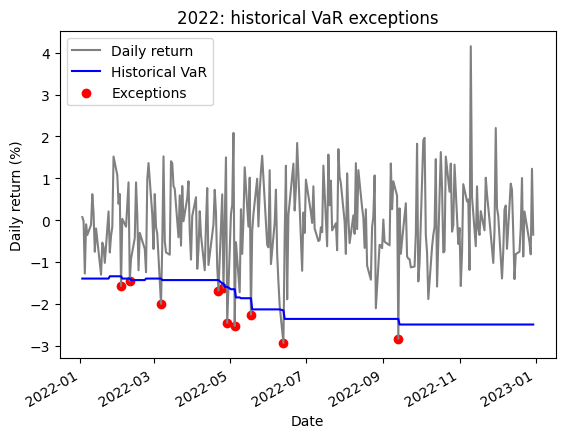

In [ ]:
(data_22_hist["portfolio"] * 100).plot(color="grey", label="Daily return")
(data_22_hist["var_hist"] * 100).plot(color="blue", label="Historical VaR")
plt.scatter(exc_22_hist.index, exc_22_hist["portfolio"] * 100, color="red", label="Exceptions")
plt.ylabel("Daily return (%)")
plt.title("2022: historical VaR exceptions")
plt.legend()
plt.show()

## Parametric (normal) VaR

In [ ]:
mu = portfolio.rolling(window).mean()
sigma = portfolio.rolling(window).std()
var_norm = (mu + sigma * norm.ppf(alpha)).shift(1)
print(var_norm.tail())
print(f"Missing values (first window): {var_norm.isna().sum()}")

Date
2022-12-23   -0.023815
2022-12-27   -0.023807
2022-12-28   -0.023837
2022-12-29   -0.023893
2022-12-30   -0.023914
dtype: float64
Missing values (first window): 250


In [ ]:
backtest_data["var_norm"] = var_norm
print(backtest_data.tail())
backtest_data.loc["2022"].isna().sum()

            portfolio  var_hist  var_norm
Date                                     
2022-12-23   0.002068 -0.024935 -0.023815
2022-12-27  -0.005265 -0.024935 -0.023807
2022-12-28  -0.008156 -0.024935 -0.023837
2022-12-29   0.012283 -0.024935 -0.023893
2022-12-30  -0.003468 -0.024935 -0.023914


,0
portfolio,0
var_hist,0
var_norm,0


In [ ]:
exceptions_norm = backtest_data.loc["2022", "portfolio"] < backtest_data.loc["2022", "var_norm"]
print(exceptions_norm.head())
data_22_norm = backtest_data.loc["2022", ["portfolio", "var_norm"]]
exc_22_norm = data_22_norm.loc[exceptions_norm]
print(exc_22_norm)

Date
2022-01-03    False
2022-01-04    False
2022-01-05     True
2022-01-06    False
2022-01-07    False
dtype: bool
            portfolio  var_norm
Date                           
2022-01-05  -0.012757 -0.011012
2022-01-18  -0.013051 -0.011265
2022-02-03  -0.015714 -0.011518
2022-02-10  -0.014475 -0.011857
2022-02-23  -0.012429 -0.012083
2022-03-07  -0.020009 -0.012011
2022-04-22  -0.016852 -0.013724
2022-04-26  -0.016141 -0.014014
2022-04-29  -0.024570 -0.014375
2022-05-05  -0.025286 -0.015134
2022-05-09  -0.017241 -0.015619
2022-05-18  -0.022582 -0.015747
2022-06-10  -0.020494 -0.016909
2022-06-13  -0.029338 -0.017252
2022-06-16  -0.018899 -0.017901
2022-08-26  -0.021056 -0.019513
2022-09-13  -0.028338 -0.020041


In [ ]:
expected_count_norm = len(data_22_norm) * alpha
actual_count_norm = exceptions_norm.sum()
print(f"Exceptions in 2022 (parametric normal): {actual_count_norm} (expected: {expected_count_norm:.2f})")

Exceptions in 2022 (parametric normal): 17 (expected: 2.51)


In [ ]:
if actual_count_norm <= 4:
    zone_norm = "GREEN"
elif actual_count_norm <= 9:
    zone_norm = "YELLOW"
else:
    zone_norm = "RED"

print(f"Basel traffic light (parametric normal): {zone_norm}")

Basel traffic light (parametric normal): RED


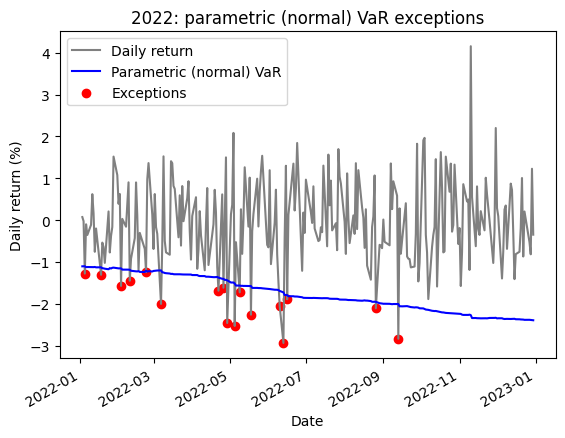

In [ ]:
(data_22_norm["portfolio"] * 100).plot(color="grey", label="Daily return")
(data_22_norm["var_norm"] * 100).plot(color="blue", label="Parametric (normal) VaR")
plt.scatter(exc_22_norm.index, exc_22_norm["portfolio"] * 100, color="red", label="Exceptions")
plt.ylabel("Daily return (%)")
plt.title("2022: parametric (normal) VaR exceptions")
plt.legend()
plt.show()

## Monte Carlo VaR (Student-t)

In [ ]:
n_sims = 10000
K = backtest_data.loc[:"2021", "portfolio"].kurtosis()
dof = 4 + 6 / K
scale_f = np.sqrt((dof - 2) / dof)
rng = np.random.default_rng(42)

print(f"Excess kurtosis (2015–2021) = {K:.2f}, degrees of freedom = {dof:.2f}, scale factor = {scale_f:.3f}")

Excess kurtosis (2015–2021) = 22.19, degrees of freedom = 4.27, scale factor = 0.729


In [ ]:
dates_22 = backtest_data.loc["2022"].index
mu_prev = mu.shift(1)
sigma_prev = sigma.shift(1)

print(f"Days in 2022: {len(dates_22)}")
print(f"Missing mu / sigma in 2022: {mu_prev.loc['2022'].isna().sum()} / {sigma_prev.loc['2022'].isna().sum()}")

Days in 2022: 251
Missing mu / sigma in 2022: 0 / 0


In [ ]:
mc_t_list = []

for day in dates_22:
    m = mu_prev.loc[day]
    s = sigma_prev.loc[day]
    raw = rng.standard_t(dof, n_sims)
    sim_returns = m + s * scale_f * raw
    mc_t_list.append(np.quantile(sim_returns, alpha))

var_t_mc = pd.Series(mc_t_list, index=dates_22)
print(var_t_mc.head())

Date
2022-01-03   -0.012146
2022-01-04   -0.012961
2022-01-05   -0.012337
2022-01-06   -0.012497
2022-01-07   -0.013133
dtype: float64


In [ ]:
var_t_formula = mu_prev.loc["2022"] + sigma_prev.loc["2022"] * scale_f * student_t.ppf(alpha, dof)
ratio_formula = var_t_mc / var_t_formula
print(f"Simulated / formula VaR: mean {ratio_formula.mean():.3f}, std {ratio_formula.std():.3f}, "
      f"min {ratio_formula.min():.3f}, max {ratio_formula.max():.3f}")

Simulated / formula VaR: mean 0.998, std 0.028, min 0.913, max 1.079


In [ ]:
backtest_data["var_t_mc"] = var_t_mc
exceptions_mc_t = backtest_data.loc["2022", "portfolio"] < backtest_data.loc["2022", "var_t_mc"]
print(exceptions_mc_t.head())
data_22_mc_t = backtest_data.loc["2022", ["portfolio", "var_t_mc"]]
exc_22_mc_t = data_22_mc_t.loc[exceptions_mc_t]
print(exc_22_mc_t)

Date
2022-01-03    False
2022-01-04    False
2022-01-05     True
2022-01-06    False
2022-01-07    False
dtype: bool
            portfolio  var_t_mc
Date                           
2022-01-05  -0.012757 -0.012337
2022-01-18  -0.013051 -0.012642
2022-02-03  -0.015714 -0.012745
2022-02-10  -0.014475 -0.013570
2022-03-07  -0.020009 -0.013593
2022-04-22  -0.016852 -0.015557
2022-04-26  -0.016141 -0.015916
2022-04-29  -0.024570 -0.016278
2022-05-05  -0.025286 -0.017543
2022-05-18  -0.022582 -0.018055
2022-06-10  -0.020494 -0.019049
2022-06-13  -0.029338 -0.019031
2022-09-13  -0.028338 -0.022189


In [ ]:
expected_count_mc_t = len(data_22_mc_t) * alpha
actual_count_mc_t = exceptions_mc_t.sum()
print(f"Exceptions in 2022 (Student-t MC): {actual_count_mc_t} (expected: {expected_count_mc_t:.2f})")

Exceptions in 2022 (Student-t MC): 13 (expected: 2.51)


In [ ]:
if actual_count_mc_t <= 4:
    zone_mc_t = "GREEN"
elif actual_count_mc_t <= 9:
    zone_mc_t = "YELLOW"
else:
    zone_mc_t = "RED"

print(f"Basel traffic light (Student-t MC): {zone_mc_t}")

Basel traffic light (Student-t MC): RED


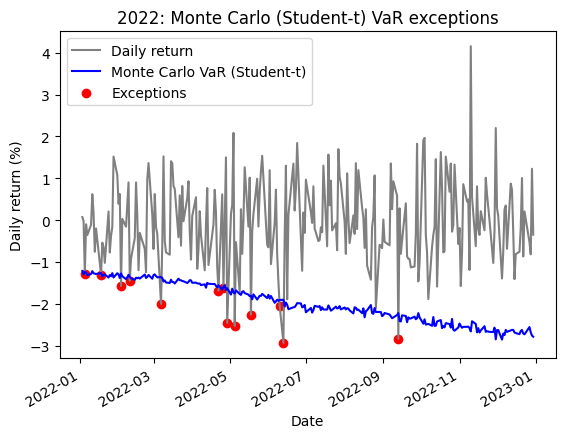

In [ ]:
(data_22_mc_t["portfolio"] * 100).plot(color="grey", label="Daily return")
(data_22_mc_t["var_t_mc"] * 100).plot(color="blue", label="Monte Carlo VaR (Student-t)")
plt.scatter(exc_22_mc_t.index, exc_22_mc_t["portfolio"] * 100, color="red", label="Exceptions")
plt.ylabel("Daily return (%)")
plt.title("2022: Monte Carlo (Student-t) VaR exceptions")
plt.legend()
plt.show()

#Why did the models fail? Stock-Bond correlation

In [ ]:
corr_roll = returns["SPY"].rolling(window).corr(returns["AGG"])

print(f"Missing values (first window): {corr_roll.isna().sum()}")
print(f"Correlation on first day of 2022: {corr_roll.loc['2022'].iloc[0]:.2f}")
print(f"Correlation on last day of 2022: {corr_roll.loc['2022'].iloc[-1]:.2f}")

Missing values (first window): 249
Correlation on first day of 2022: 0.04
Correlation on last day of 2022: 0.32


In [ ]:
corr_2021 = returns.loc["2021"].corr().loc["SPY", "AGG"]
corr_2022 = returns.loc["2022"].corr().loc["SPY", "AGG"]

print(f"SPY–AGG correlation in 2021: {corr_2021:.2f}")
print(f"SPY–AGG correlation in 2022: {corr_2022:.2f}")

SPY–AGG correlation in 2021: 0.04
SPY–AGG correlation in 2022: 0.32


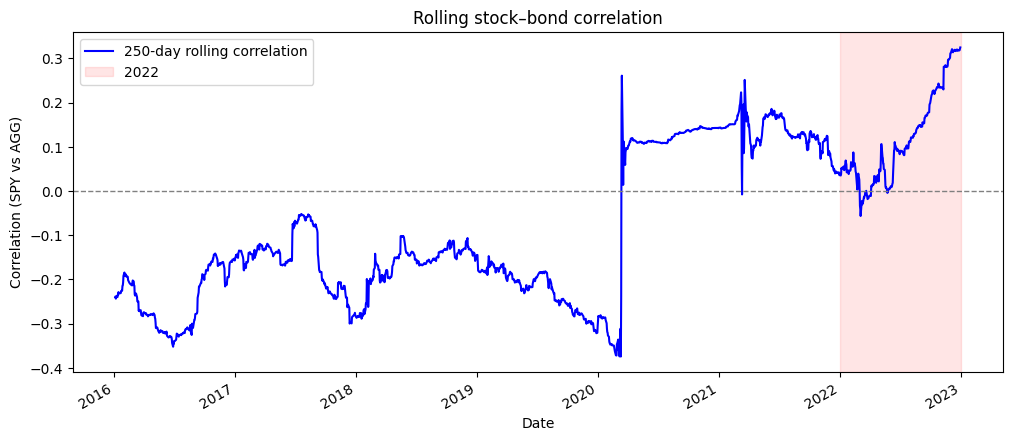

In [ ]:
corr_roll.loc["2016":].plot(color="blue",figsize=(12, 5), label="250-day rolling correlation")
plt.axhline(0, color="grey", linestyle="dashed", linewidth=1)
plt.axvspan("2022-01-01", "2022-12-31", color="red", alpha=0.1, label="2022")
plt.ylabel("Correlation (SPY vs AGG)")
plt.title("Rolling stock–bond correlation")
plt.legend()
plt.show()